# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`transformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Він лежить в архіві демо-матеріалів лекції 4 — посилання «Демо-матеріали (zip)» є в картці лекції на головній сторінці курсу. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### 0.2. Мої відповіді:

#### 1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?

Це легше для пам'яті і на межах віршів не створювалися б штучні злиття.

#### 2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))

1. Нормалізація: попереднє очищенні та приведення тексту до канонічного вигляду
2. Пре-токенізація:

#### 3. Що таке `"<unk>", "<eos>"` в 2.1.?

`<unk>` (Unknown token): використовується для позначення невідомих символів

`<eos>` (End-of_Sequence): позначає кінець окремого документа

#### 4. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).

```
VOCAB_SIZE=16000 | Середня довжина вірша: 1028.1 токенів | <unk>: 0.00%
VOCAB_SIZE= 5000 | Середня довжина вірша: 1206.4 токенів | <unk>: 0.00%
```

Середня кількість токенів на вірш зросла на 17,3%, кількість невідомих токенів не змінилася.

`<unk>` не зростає BPE розскладає символи на байти і працює з байтами, і всі символи які туди попадуть перетворяться на ті самі байти, тому невідомих символів немає.

Менший словник означає меншу кількість ітерацій злиття частих пар, тому слова розбиваються на менші частини, тому довжина тексту в токенах збільшується.

#### 4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?

Після кодування всі вірші об'єднуються в один тензор, а `<eos>` розділяє вірші між собою, без нього модель навчатиметься продовжувати кінець попереднього рядка початком наступного, змішаються стилі і модель під час генерації не знатимено коли завершити вірш.

#### 5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?

Формат: torch.LongTensor

```tensor([  544, 10109,   567,  ...,    13,  1045,  2686])```

Це ідентифікатор токенів (`token_id`) тексту

#### 6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.

```
assert xb.shape == (BATCH_SIZE, CONTEXT_LEN) and yb.shape == (BATCH_SIZE, CONTEXT_LEN), "Неправильна форма батчу"
assert torch.equal(xb[:, 1:], yb[:, :-1]), "Порушено зсув на 1 токен між входом x та таргетом y!"
```

#### 7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?

Матриця оцінок уваги побудовани так, що на рядках розсташовані токени-запити, а в стовпцях токени-ключі, і в авторегресійній моделі токен має дивитися лише на себе та попередні токени, і саме них показує нижньотрикутна матриця.

Без маски під час тренування модель бачила б наступний токен і видавала б його, а не вивчала закономірності.

#### 8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.

Вони збігаються коли кількість ітерацій недостатня для перенавчання, тоді `val_loss` спадає до останньої ітерації

Вони не збігаються коли настає перенавчання, тоді `train_loss` продовжує спадати, а `val_loss` починає зростати.

У нашому випадку найкращим чекпоінтом виявився 7750 (з 8000)

```
iter  7750  train_loss=5.598  val_loss=5.674  (4.8 хв)
iter  7999  train_loss=5.581  val_loss=5.685  (5.0 хв)

Тренування завершено за 5.0 хв
Найкращий чекпоінт: iter 7750  (val_loss=5.674)
```


#### 10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?

```
iter  7900  train_loss=5.586  val_loss=5.672  (7.8 хв)
iter  7950  train_loss=5.570  val_loss=5.664  (7.9 хв)
iter  7999  train_loss=5.575  val_loss=5.670  (7.9 хв)

Тренування завершено за 7.9 хв
Найкращий чекпоінт: iter 7950  (val_loss=5.664)
```

Це коштувало додатнових 2.9 хв на GPU L4, це 58%.

На графіку кількість точок зросла у 5 разів, але він не став гладкішим, а з'явиилося більше дрібних коливань. З огляду на час та результату робити його мешим не доцільно.

#### 11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.

$$p_i(T) = \frac{\exp\left(\frac{z_i}{T}\right)}{\sum_{j=1}^{V} \exp\left(\frac{z_j}{T}\right)}$$

При низькій температурі різниця між логітами збільшується.

З дуже високою температурою розподіл наближається до рівномірного.

#### 12. За що саме відповідає параметр `top_p`?

Він обмежує кількість можливих токенів так, щоб сума їхніх ймовірностей не перевищувала `top_p`.

#### 13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

З увімкненими міркуваннями модель почала вставляти ntu `<think>` з роздумами англійською, і через обмеження в максимальну кількість токенів навіть не дійшла до реальної відповіді.

```
--- temperature=0.2, top_p=0.1 ---
<think>
Okay, the user wants me to continue the sentence: "Якось уночі студент Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка..."

First, I need to make sure I understand the context. The sentence is in Ukrainian, so I should maintain the language. The story is about a student from the Kharkiv Polytechnic University (though the name is "Житомирської", which is Khmelnytskyi, not Kharkiv. Wait, maybe it's a typo? Or maybe it's correct. Let me check. "Житомирської" is Khmelnytskyi, but the user might have intended Kharkiv. But I should stick to the original text. So the student is from Khmelnytskyi Polytechnic.

The sentence starts with the student waking up from a strange noise. He gets up from bed. Now, I need to continue the story. The user probably wants a coherent continuation that builds on the initial setup. The next part should describe what the student does after getting up. Maybe he investigates the noise, finds something unusual, leading to a mystery or a twist.

Possible directions: The noise could be from an animal, a supernatural element, or something mechanical. Since it's a student, maybe it

--- temperature=0.8, top_p=0.6 ---
<think>
Okay, the user wants me to continue the sentence: "Якось уночі студент Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка..." So, first, I need to make sure I understand the original sentence correctly. It's a Ukrainian sentence, so I should maintain the language and context.

The sentence starts with a student from the Kharkiv Polytechnic University waking up from a strange noise. The next part is "Він підвівся з ліжка..." which translates to "He got up from the bed..." So the continuation should follow logically.

I need to think about what happens next. The student is waking up, so maybe he investigates the noise. Since it's a strange noise, perhaps it's something supernatural or mysterious. Maybe the noise is coming from the hallway or another room. The student might check the source, find something unusual, like a shadow or a hidden object. Maybe there's a hidden room or a secret passage. Alternatively, it could be a supernatural element, like a ghost or a spirit. But since it's a student, maybe it's more of a mystery or a prank. However, the original sentence mentions a "дивний шум" (strange noise), so it's more likely to be something mysterious.

I should

--- temperature=1.4, top_p=0.8 ---
<think>
Okay, the user wants me to continue the sentence: "Якось уночі студент Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка..." So, I need to think about what happens next in the story.

First, the original sentence is in Ukrainian, so I should maintain the language. The main elements are a student from the Kharkiv Polytechnic University (Wait, no, the user wrote "Житомирської", which is Kharkiv? Wait, no, Житомир is a city in Ukraine, so it's Kharkiv Polytechnic University? Or maybe the user meant another university? Wait, no, Житомир is a city in the Khmelnytskyi region, but the main Kharkiv Polytechnic University is in Kharkiv. Maybe it's a typo, but I should go with what's written.

The student wakes up to a strange noise, gets up from bed. What would happen next? The noise is strange, so maybe it's a supernatural or unusual event. The student might check the source of the noise. Maybe it's a hidden room, a secret passage, or something mysterious. Alternatively, maybe the noise is from an experiment, but since it's a university, perhaps a scientific event. But the
```


---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

In [ ]:
!pip install -q datasets tokenizers "transformers[sentencepiece]" evaluate seqeval gradio accelerate

import sys
import os
import gc
import json
import time
import math
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from torch.utils.tensorboard import SummaryWriter

SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)
print("Seed зафіксовано:", SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо пристрій:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab3"
else:
    ARTIFACT_DIR = "."

MODELS_DIR = os.path.join(ARTIFACT_DIR, "models")
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
TOKENIZERS_DIR = os.path.join(ARTIFACT_DIR, "tokenizers")
RESULTS_PATH = os.path.join(ARTIFACT_DIR, "results.csv")

os.makedirs(ARTIFACT_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RUNS_DIR, exist_ok=True)
os.makedirs(TOKENIZERS_DIR, exist_ok=True)

print("Артефакти зберігаються в:", ARTIFACT_DIR)
print("Збережені моделі:       ", MODELS_DIR)
print("Логи TensorBoard:       ", RUNS_DIR)
print("Токенізатори:           ", TOKENIZERS_DIR)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
Seed зафіксовано: 42
Використовуємо пристрій: cuda
GPU: NVIDIA L4
Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab3
Збережені моделі:        /content/drive/MyDrive/ai_systems/lab3/models
Логи TensorBoard:        /content/drive/MyDrive/ai_systems/lab3/runs
Токенізатори:            /content/drive/MyDrive/ai_systems/lab3/tokenizers


In [ ]:
SAMPLE_SIZE = 20000

streamed_wiki = load_dataset(
    "wikimedia/wikipedia",
    "20231101.uk",
    split="train",
    streaming=True
).take(SAMPLE_SIZE)

rows = list(streamed_wiki)
wiki_df = pd.DataFrame(rows)

print(f"Завантажено статей: {len(wiki_df)}")
print("Колонки датасету:", wiki_df.columns.tolist())

articles_list = wiki_df["text"].dropna().tolist()
corpus_text = "\n\n".join(articles_list)

print(f"Розмір корпусу: {len(corpus_text):,} символів")
print("Перші 500 символів:\n", corpus_text[:500])

README.md:   0%|          | 0.00/131k [00:00<?, ?B/s]

Завантажено статей: 20000
Колонки датасету: ['id', 'url', 'title', 'text']
Розмір корпусу: 125,952,534 символів
Перші 500 символів:
 Геогра́фія, або заст. земле́пис (від  — опис Землі; де  — Земля і  — писати, описувати) — система наук, що вивчає географічну оболонку Землі (епігеосферу), її просторову природну і соціально-економічну різноманітність, господарство і населення планети, окремих її регіонів та країн, а також зв'язки між природним середовищем і діяльністю людини. В сучасному розумінні поняття «географія» заміщено поняттям «географічні науки».

Поняття 
Уперше термін «географія» був запропонований давньогрецьким гео


In [ ]:
words = corpus_text.split()
unique_words = set(w.lower() for w in words)

print("Слів (з повторами):   ", len(words))
print("Унікальних слів:      ", len(unique_words))
print("Приклад уривку:\n")
print(corpus_text[:500])


Слів (з повторами):    17071239
Унікальних слів:       1450963
Приклад уривку:

Геогра́фія, або заст. земле́пис (від  — опис Землі; де  — Земля і  — писати, описувати) — система наук, що вивчає географічну оболонку Землі (епігеосферу), її просторову природну і соціально-економічну різноманітність, господарство і населення планети, окремих її регіонів та країн, а також зв'язки між природним середовищем і діяльністю людини. В сучасному розумінні поняття «географія» заміщено поняттям «географічні науки».

Поняття 
Уперше термін «географія» був запропонований давньогрецьким гео


---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

In [ ]:
from transformers import AutoTokenizer
from tokenizers import Tokenizer, models, normalizers, pre_tokenizers, decoders, trainers

sample_texts = articles_list[:10000]
COMPARE_VOCAB_SIZE = 10000

old_tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
new_tokenizer = old_tokenizer.train_new_from_iterator(sample_texts, vocab_size=COMPARE_VOCAB_SIZE)
print("Розмір словника (train_new_from_iterator):", len(new_tokenizer))

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Розмір словника (train_new_from_iterator): 10008


In [ ]:
tokens = old_tokenizer.tokenize(articles_list[0][:400])
print(f"Кількість токенів (Qwen2.5): {len(tokens)}")
tokens[:25]

Кількість токенів (Qwen2.5): 210


['Ðĵ',
 'Ðµ',
 'Ð¾Ð³',
 'ÑĢÐ°',
 'Ìģ',
 'ÑĦ',
 'Ñĸ',
 'Ñı',
 ',',
 'ĠÐ°',
 'Ð±Ð¾',
 'ĠÐ·Ð°',
 'ÑģÑĤ',
 '.',
 'ĠÐ·',
 'ÐµÐ¼',
 'Ð»Ðµ',
 'Ìģ',
 'Ð¿Ð¸Ñģ',
 'Ġ(',
 'Ð²',
 'Ñĸ',
 'Ð´',
 'Ġ',
 'Âł']

In [ ]:
tokens = new_tokenizer.tokenize(articles_list[0][:400])
print(f"Кількість токенів (Навчений BPE): {len(tokens)}")
tokens[:25]

Кількість токенів (Навчений BPE): 108


['ÐĵÐµ',
 'Ð¾Ð³ÑĢÐ°',
 'Ìģ',
 'ÑĦ',
 'ÑĸÑı',
 ',',
 'ĠÐ°Ð±Ð¾',
 'ĠÐ·Ð°ÑģÑĤ',
 '.',
 'ĠÐ·ÐµÐ¼',
 'Ð»Ðµ',
 'Ìģ',
 'Ð¿Ð¸Ñģ',
 'Ġ(',
 'Ð²ÑĸÐ´',
 'Ġ',
 'Âł',
 'âĢĶ',
 'ĠÐ¾Ð¿Ð¸Ñģ',
 'ĠÐĹÐµÐ¼Ð»Ñĸ',
 ';',
 'ĠÐ´Ðµ',
 'Ġ',
 'Âł',
 'âĢĶ']

In [ ]:
tok_bpe = Tokenizer(models.BPE(unk_token="<unk>"))
tok_bpe.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
tok_bpe.decoder = decoders.ByteLevel()
trainer_bpe = trainers.BpeTrainer(vocab_size=COMPARE_VOCAB_SIZE, special_tokens=["<unk>", "<eos>"])
tok_bpe.train_from_iterator(sample_texts, trainer=trainer_bpe)

In [ ]:
tok_wp = Tokenizer(models.WordPiece(unk_token="[UNK]"))
tok_wp.normalizer = normalizers.NFKC()
tok_wp.pre_tokenizer = pre_tokenizers.Whitespace()
tok_wp.decoder = decoders.WordPiece(prefix="##")
trainer_wp = trainers.WordPieceTrainer(vocab_size=COMPARE_VOCAB_SIZE, special_tokens=["[UNK]", "[PAD]", "[CLS]", "[SEP]", "[MASK]"])
tok_wp.train_from_iterator(sample_texts, trainer=trainer_wp)

In [ ]:
tok_uni = Tokenizer(models.Unigram())
tok_uni.normalizer = normalizers.NFKC()
tok_uni.pre_tokenizer = pre_tokenizers.Metaspace()
tok_uni.decoder = decoders.Metaspace()
trainer_uni = trainers.UnigramTrainer(vocab_size=COMPARE_VOCAB_SIZE, special_tokens=["<unk>", "<eos>"], unk_token="<unk>")
tok_uni.train_from_iterator(sample_texts, trainer=trainer_uni)

In [ ]:
test_sample_text = "\n".join(articles_list[500:520])
freq_word = "Україна"
rare_word = "термодинамічний"

comparison_rows = []
for name, tok in [("BPE", tok_bpe), ("WordPiece", tok_wp), ("Unigram", tok_uni)]:
    enc_sample = tok.encode(test_sample_text)
    enc_freq = tok.encode(freq_word)
    enc_rare = tok.encode(rare_word)

    comparison_rows.append({
        "Алгоритм": name,
        "Розмір словника": tok.get_vocab_size(),
        "Кількість токенів на зразку": len(enc_sample.ids),
        f"Токени ('{freq_word}')": f"{len(enc_freq.tokens)} ({enc_freq.tokens})",
        f"Токени ('{rare_word}')": f"{len(enc_rare.tokens)} ({enc_rare.tokens})"
    })

comp_df = pd.DataFrame(comparison_rows)
display(comp_df)

,Алгоритм,Розмір словника,Кількість токенів на зразку,Токени ('Україна'),Токени ('термодинамічний')
0,BPE,10000,21764,1 (['Ð£ÐºÑĢÐ°ÑĹÐ½Ð°']),"5 (['ÑĤÐµÑĢ', 'Ð¼', 'Ð¾Ð´Ð¸', 'Ð½Ð°Ð¼', 'ÑĸÑĩÐ..."
1,WordPiece,10000,20689,1 (['Україна']),"5 (['тер', '##мо', '##дин', '##ам', '##ічний'])"
2,Unigram,10000,20985,1 (['▁Україна']),"3 (['▁термо', 'динам', 'ічний'])"


---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

In [ ]:
def get_or_prepare_wiki_data(
    articles: list[str],
    vocab_size: int = 8000,
    data_cache: dict = None,
    batch_size: int = 1000,
):
    """Тренує (або дістає з кешу) BPE-токенізатор для заданого vocab_size,
    зберігає його на диск і готує тензори train/val."""
    if data_cache is not None and vocab_size in data_cache:
        print(f"[VOCAB={vocab_size}] Використовуємо закешований токенізатор та тензори.")
        return data_cache[vocab_size]

    tok_path = os.path.join(TOKENIZERS_DIR, f"bpe_v{vocab_size}.json")
    tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))
    tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tokenizer.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=["<unk>", "<eos>"])
    tokenizer.train_from_iterator(articles, trainer=trainer)
    tokenizer.save(tok_path)

    eos_id = tokenizer.token_to_id("<eos>")
    if eos_id is None:
        raise ValueError("Токенізатор повинен містити спеціальний токен '<eos>'!")

    chunks = []
    for start in range(0, len(articles), batch_size):
        batch = articles[start:start + batch_size]
        encodings = tokenizer.encode_batch(batch)
        for enc in encodings:
            chunks.append(np.array(enc.ids + [eos_id], dtype=np.int32))
        del encodings

    token_ids = np.concatenate(chunks)
    del chunks
    gc.collect()

    data_tensor = torch.from_numpy(token_ids.astype(np.int64))
    del token_ids
    gc.collect()

    split_idx = int(len(data_tensor) * 0.9)
    train_d = data_tensor[:split_idx]
    val_d = data_tensor[split_idx:]
    print(f"[VOCAB={tokenizer.get_vocab_size()}] Усього токенів: {len(data_tensor):,} | train: {len(train_d):,} | val: {len(val_d):,}")

    result_tuple = (tokenizer, train_d, val_d)
    if data_cache is not None:
        data_cache[vocab_size] = result_tuple
    return result_tuple


class AttentionHead(nn.Module):
    def __init__(self, embed_dim: int, head_dim: int, context_len: int, dropout: float):
        super().__init__()
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("causal_mask", torch.tril(torch.ones(context_len, context_len)))

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.query(x), self.key(x), self.value(x)
        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])
        scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = self.dropout(F.softmax(scores, dim=-1))
        return weights @ v


class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        head_dim = embed_dim // n_heads
        self.heads = nn.ModuleList([AttentionHead(embed_dim, head_dim, context_len, dropout) for _ in range(n_heads)])
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.dropout(self.proj(out))


class FeedForward(nn.Module):
    def __init__(self, embed_dim: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        self.attention = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.feed_forward = FeedForward(embed_dim, dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x


class MiniGPT(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int, n_heads: int, n_layers: int, context_len: int, dropout: float):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[TransformerBlock(embed_dim, n_heads, context_len, dropout) for _ in range(n_layers)])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.token_embedding(idx) + self.position_embedding(torch.arange(T, device=idx.device))
        x = self.final_norm(self.blocks(x))
        logits = self.lm_head(x)
        loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1)) if targets is not None else None
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens: int, temperature: float = 0.8, top_k: int = 40):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context_len:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = float("-inf")
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx


def create_minigpt_model(vocab_size: int, cfg: dict) -> MiniGPT:
    embed_dim = cfg["embed_dim"]
    n_heads = cfg["n_heads"]
    assert embed_dim % n_heads == 0, f"embed_dim ({embed_dim}) має ділитися на n_heads ({n_heads})"
    return MiniGPT(
        vocab_size=vocab_size,
        embed_dim=embed_dim,
        n_heads=n_heads,
        n_layers=cfg["n_layers"],
        context_len=cfg["context_len"],
        dropout=cfg.get("dropout", 0.1),
    )

In [ ]:
@torch.no_grad()
def generate_from_prompt(
    model: MiniGPT,
    tokenizer: Tokenizer,
    prompt: str,
    max_new_tokens: int = 50,
    temperature: float = 0.8,
    top_k: int = 40,
    device: str | torch.device = None,
) -> str:
    if device is None:
        device = next(model.parameters()).device

    model.eval()
    encoded = tokenizer.encode(prompt).ids
    if not encoded:
        raise ValueError("Промпт після токенізації порожній.")

    prompt_ids = torch.tensor([encoded], dtype=torch.long, device=device)
    out_ids = model.generate(
        prompt_ids,
        max_new_tokens=max_new_tokens,
        temperature=temperature,
        top_k=top_k,
    )
    return tokenizer.decode(out_ids[0].tolist())


def generate_with_saved_variant(
    variant_name: str,
    prompt: str,
    max_new_tokens: int = 80,
    temperature: float = 0.7,
    top_k: int = 40,
) -> str:
    """Завантажує збережений токенізатор і найкращий чекпоінт варіанта з MODELS_DIR та генерує текст."""
    meta_path = os.path.join(MODELS_DIR, f"{variant_name}_meta.json")
    with open(meta_path, "r", encoding="utf-8") as f:
        meta = json.load(f)

    tokenizer = Tokenizer.from_file(meta["tokenizer_path"])
    model = create_minigpt_model(meta["vocab_size"], meta).to(device)
    model.load_state_dict(torch.load(meta["ckpt_path"], map_location=device))
    model.eval()

    text = generate_from_prompt(
        model=model,
        tokenizer=tokenizer,
        prompt=prompt,
        max_new_tokens=max_new_tokens,
        temperature=temperature,
        top_k=top_k,
        device=device,
    )

    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return text


def train_and_log_minigpt(
    cfg: dict,
    articles: list[str],
    data_cache: dict = None,
    common_prompt: str = "Україна — це держава у Східній Європі, яка",
    skip_if_exists: bool = False,
) -> dict:
    """Єдиний пайплайн тренування, логування в TensorBoard та збереження чекпоінта варіанта."""
    variant_name = cfg["variant_name"]
    ckpt_filename = cfg.get("ckpt_filename", f"{variant_name}.pt")
    ckpt_path = os.path.join(MODELS_DIR, ckpt_filename)
    meta_path = os.path.join(MODELS_DIR, f"{variant_name}_meta.json")

    if skip_if_exists and os.path.exists(ckpt_path) and os.path.exists(meta_path):
        print(f"[{variant_name}] Завантажуємо вже збережені результати з {ckpt_path}")
        with open(meta_path, "r", encoding="utf-8") as f:
            return json.load(f)

    set_seed(cfg.get("seed", SEED))
    print(f"\n{'='*60}\nТренування варіанта: {variant_name}\n{'='*60}")

    vocab_size = cfg["vocab_size"]
    context_len = cfg["context_len"]
    embed_dim = cfg["embed_dim"]
    n_heads = cfg["n_heads"]
    n_layers = cfg["n_layers"]
    max_iters = cfg.get("max_iters", 2000)
    eval_interval = cfg.get("eval_interval", 200)
    eval_iters = cfg.get("eval_iters", 40)
    batch_size = cfg.get("batch_size", 64)
    lr = cfg.get("lr", 3e-4)
    dropout = cfg.get("dropout", 0.1)

    tokenizer, train_d, val_d = get_or_prepare_wiki_data(
        articles=articles,
        vocab_size=vocab_size,
        data_cache=data_cache,
    )
    actual_vocab_size = tokenizer.get_vocab_size()
    tok_path = os.path.join(TOKENIZERS_DIR, f"bpe_v{vocab_size}.json")

    def get_batch(split: str):
        source = train_d if split == "train" else val_d
        ix = torch.randint(len(source) - context_len - 1, (batch_size,))
        x = torch.stack([source[i:i + context_len] for i in ix])
        y = torch.stack([source[i + 1:i + context_len + 1] for i in ix])
        return x.to(device), y.to(device)

    model = create_minigpt_model(actual_vocab_size, cfg).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"Параметрів моделі: {n_params:,} | ctx={context_len}, dim={embed_dim}, heads={n_heads}, layers={n_layers}, lr={lr}")

    @torch.no_grad()
    def estimate_loss():
        model.eval()
        out = {}
        for split in ("train", "val"):
            losses = torch.zeros(eval_iters)
            for i in range(eval_iters):
                xb, yb = get_batch(split)
                _, loss = model(xb, yb)
                losses[i] = loss.item()
            out[split] = losses.mean().item()
        model.train()
        return out

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr)
    writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, variant_name))

    train_losses, val_losses, eval_steps = [], [], []
    best_val_loss = float("inf")
    best_iter = 0
    start_t = time.time()

    for it in range(max_iters):
        xb, yb = get_batch("train")
        _, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        if it % eval_interval == 0 or it == max_iters - 1:
            losses = estimate_loss()
            train_losses.append(round(losses["train"], 4))
            val_losses.append(round(losses["val"], 4))
            eval_steps.append(it)

            writer.add_scalar("Loss/train", losses["train"], it)
            writer.add_scalar("Loss/val", losses["val"], it)
            print(f"[{variant_name}] iter {it:4d} | train_loss={losses['train']:.3f} | val_loss={losses['val']:.3f} | {(time.time()-start_t)/60:.1f} хв")

            if losses["val"] < best_val_loss:
                best_val_loss = losses["val"]
                best_iter = it
                torch.save(model.state_dict(), ckpt_path)

    writer.close()
    elapsed_min = round((time.time() - start_t) / 60, 2)

    # Завантажуємо найкращий чекпоінт для генерації
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.eval()

    generated_text = generate_from_prompt(
        model=model,
        tokenizer=tokenizer,
        prompt=common_prompt,
        max_new_tokens=60,
        temperature=0.8,
        top_k=40,
        device=device,
    )

    # Звільняємо GPU-пам'ять одразу після завершення варіанта
    del model, optimizer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    result_record = {
        "section": "3_minigpt",
        "model_or_variant": variant_name,
        "ckpt_filename": ckpt_filename,
        "ckpt_path": ckpt_path,
        "tokenizer_path": tok_path,
        "vocab_size": actual_vocab_size,
        "context_len": context_len,
        "embed_dim": embed_dim,
        "n_heads": n_heads,
        "n_layers": n_layers,
        "dropout": dropout,
        "max_iters": max_iters,
        "lr": lr,
        "n_params": n_params,
        "best_iter": best_iter,
        "best_val_loss": round(best_val_loss, 4),
        "elapsed_min": elapsed_min,
        "eval_steps": eval_steps,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "generated_sample": generated_text,
    }

    with open(meta_path, "w", encoding="utf-8") as f:
        json.dump(result_record, f, ensure_ascii=False, indent=2)

    return result_record

In [ ]:
COMMON_PROMPT = "Україна — це держава у Східній Європі, яка"
SKIP_IF_EXISTS = False

minigpt_configs = [
    {
        "variant_name": "minigpt_v1_v8k_ctx64_L3",
        "ckpt_filename": "minigpt_v1.pt",
        "vocab_size": 8000,
        "context_len": 64,
        "embed_dim": 128,
        "n_heads": 4,
        "n_layers": 3,
        "max_iters": 2000,
        "lr": 3e-4,
    },
    {
        "variant_name": "minigpt_v2_v16k_ctx128_L4",
        "ckpt_filename": "minigpt_v2.pt",
        "vocab_size": 16000,
        "context_len": 128,
        "embed_dim": 128,
        "n_heads": 4,
        "n_layers": 4,
        "max_iters": 4000,
        "lr": 3e-4,
    },
    {
        "variant_name": "gpt_small",
        "ckpt_filename": "gpt_small.pt",
        "vocab_size": 8000,
        "context_len": 256,
        "embed_dim": 384,
        "n_heads": 6,
        "n_layers": 6,
        "max_iters": 6000,
        "lr": 3e-4,
    },
]

all_minigpt_results = {}
data_cache = {}

for cfg in minigpt_configs:
    name = cfg["variant_name"]
    all_minigpt_results[name] = train_and_log_minigpt(
        cfg=cfg,
        articles=articles_list,
        data_cache=data_cache,
        common_prompt=COMMON_PROMPT,
        skip_if_exists=SKIP_IF_EXISTS,
    )
    r = all_minigpt_results[name]
    print(f"-> {name}: best_val_loss={r['best_val_loss']:.4f} (iter {r['best_iter']}), час={r['elapsed_min']} хв")


Тренування варіанта: minigpt_v1_v8k_ctx64_L3
[VOCAB=8000] Усього токенів: 39,392,533 | train: 35,453,279 | val: 3,939,254
Параметрів моделі: 2,658,112 | ctx=64, dim=128, heads=4, layers=3, lr=0.0003
[minigpt_v1_v8k_ctx64_L3] iter    0 | train_loss=9.132 | val_loss=9.127 | 0.0 хв
[minigpt_v1_v8k_ctx64_L3] iter  200 | train_loss=7.411 | val_loss=7.429 | 0.1 хв
[minigpt_v1_v8k_ctx64_L3] iter  400 | train_loss=7.212 | val_loss=7.243 | 0.2 хв
[minigpt_v1_v8k_ctx64_L3] iter  600 | train_loss=6.997 | val_loss=7.050 | 0.3 хв
[minigpt_v1_v8k_ctx64_L3] iter  800 | train_loss=6.754 | val_loss=6.806 | 0.4 хв
[minigpt_v1_v8k_ctx64_L3] iter 1000 | train_loss=6.530 | val_loss=6.588 | 0.5 хв
[minigpt_v1_v8k_ctx64_L3] iter 1200 | train_loss=6.364 | val_loss=6.405 | 0.6 хв
[minigpt_v1_v8k_ctx64_L3] iter 1400 | train_loss=6.216 | val_loss=6.279 | 0.7 хв
[minigpt_v1_v8k_ctx64_L3] iter 1600 | train_loss=6.066 | val_loss=6.147 | 0.8 хв
[minigpt_v1_v8k_ctx64_L3] iter 1800 | train_loss=5.948 | val_loss=6.008

,model_or_variant,vocab_size,context_len,embed_dim,n_heads,n_layers,max_iters,n_params,best_val_loss,elapsed_min
2,gpt_small,8000,256,384,6,6,6000,16890944,3.8467,34.79
1,minigpt_v2_v16k_ctx128_L4,16000,128,128,4,4,4000,4920192,5.7269,3.57
0,minigpt_v1_v8k_ctx64_L3,8000,64,128,4,3,2000,2658112,5.9278,0.95


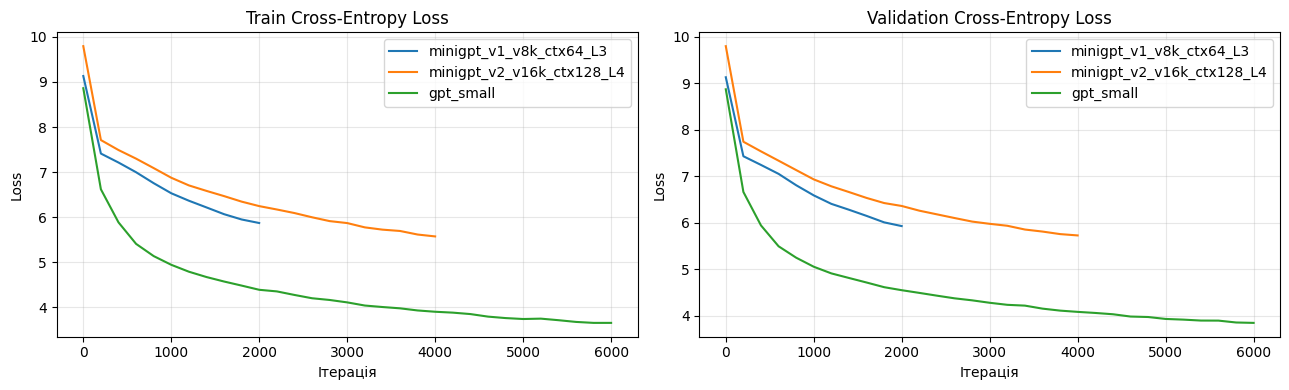

Спільний промпт: «Україна — це держава у Східній Європі, яка»

=== minigpt_v1_v8k_ctx64_L3 (best_val_loss=5.9278) ===
Україна — це держава у Східній Європі, яка у складі в Україні, що відкладання в результаті сах В.

Найбільшний, але не лише з них за допомогою складують бути кільної систем, але з яких в межах його на честь яких до того, що лише на північської.

Ох років,

=== minigpt_v2_v16k_ctx128_L4 (best_val_loss=5.7269) ===
Україна — це держава у Східній Європі, яка існує близько 15 років, з них в результаті його до складу 1941 року на рік році, до 14 квітня 1918 року. У 1685 року. Сельджальний, з династії Тан та Нова Іспанія, що був створений на півдні, що в Італії. Він також на початку 1753 році, з яких

=== gpt_small (best_val_loss=3.8467) ===
Україна — це держава у Східній Європі, яка з нею була в основному доісторичним договором. У XIV ст. за підтримки держав, в XIV ст. до н. е., в XI столітті до н. е., коли він залишався з Візантії, а потім після завершення повстання в Європі

In [ ]:
minigpt_results_df = pd.DataFrame(list(all_minigpt_results.values()))
display_cols = [
    "model_or_variant", "vocab_size", "context_len",
    "embed_dim", "n_heads", "n_layers", "max_iters",
    "n_params", "best_val_loss", "elapsed_min"
]
display(minigpt_results_df[display_cols].sort_values("best_val_loss"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, res in all_minigpt_results.items():
    axes[0].plot(res["eval_steps"], res["train_losses"], label=name)
    axes[1].plot(res["eval_steps"], res["val_losses"], label=name)

axes[0].set_title("Train Cross-Entropy Loss")
axes[0].set_xlabel("Ітерація")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Validation Cross-Entropy Loss")
axes[1].set_xlabel("Ітерація")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Спільний промпт: «{COMMON_PROMPT}»\n")
for name, res in all_minigpt_results.items():
    print(f"=== {name} (best_val_loss={res['best_val_loss']:.4f}) ===")
    print(res["generated_sample"])
    print()

best_variant_name = min(all_minigpt_results, key=lambda k: all_minigpt_results[k]["best_val_loss"])
custom_prompt = "Київ розташований в"
print(f"=== Додаткова генерація найкращою моделлю ({best_variant_name}) ===")
print(generate_with_saved_variant(best_variant_name, prompt=custom_prompt, max_new_tokens=100, temperature=0.7, top_k=50))

In [ ]:
# Вивільнення пам'яті
for var_name in [
    "data_cache", "wiki_df", "articles_list", "corpus_text", "rows",
    "sample_texts", "tok_bpe", "tok_wp", "tok_uni", "new_tokenizer", "old_tokenizer"
]:
    if var_name in globals():
        del globals()[var_name]

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"GPU пам'ять після очищення: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

_Зверніть увагу_: в межах попередніх завдань Ви могли завантажити памʼять "під завʼязку", тому для безпроблемного виконання наступних секцій вивільніть памʼять:

1. **Спершу збережіть усе потрібне на диск** — чекпоінти mini-GPT (`models/minigpt_v*.pt`), токенізатори, `results.csv`. Секції 4-6 від змінних секцій 1-3 не залежать, тож після цього їх можна сміливо видаляти.
2. **Видаліть великі обʼєкти** — моделі, оптимізатори, тензори `train_data`/`val_data`, корпус і `DataFrame`-и — і зберіть сміття:
   ```python
   import gc, torch

   del model, optimizer, train_data, val_data, corpus_text  # підставте свої імена змінних
   gc.collect()
   if torch.cuda.is_available():
       torch.cuda.empty_cache()
       print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
   ```
   Памʼять звільниться лише тоді, коли на обʼєкт не лишиться **жодного** посилання: зверніть увагу на копії в інших змінних, списках і словниках (наприклад, словник із кількома варіантами моделей).
3. **Перевірте, що памʼять справді звільнилась**: індикатор RAM/GPU вгорі праворуч.
4. **У самій секції 4 не тримайте всі pipeline-и одночасно**: кожен `pipeline(...)` завантажує окрему модель. Перевикористовуйте одну змінну (як `classifier` нижче) або робіть `del` + `gc.collect()` після кожної задачі.
5. **Стежте за диском**: моделі кешуються в `~/.cache/huggingface/hub`, і кілька моделей для summarization/translation легко займуть кілька ГБ. Переглянути й почистити кеш: `hf cache ls` / `hf cache rm <id моделі>`.

### 4.0. Запустіть приклади виконання різних NLP задач

In [ ]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9598046541213989}]
[{'label': 'POSITIVE', 'score': 0.9598046541213989}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [ ]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.8445947766304016, 0.11197735369205475, 0.04342785105109215]}

In [ ]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/326 [00:00<?, ?it/s]

... (14 outputs left out)

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'generated_text': 'In this course, we will teach you how to use VST and how to use VST.\n\n\n\n\nWe will show you how'}, {'generated_text': 'In this course, we will teach you how to use some of the same techniques as your own. First you will be able to use the following techniques'}]


In [ ]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

[transformers] RobertaForMaskedLM LOAD REPORT from: distilbert/distilroberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'score': 0.1961965560913086,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052708297967911,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [ ]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.97960186),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [ ]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("table-question-answering")
question_answerer(
    query="How many stars does the transformers repository have?",
    table={"Repository":["Transformers","Datasets","Tokenizers"],"Stars":["36542","4512","3934"],"Contributors":["651","77","34"],"Programming language":["Python","Python","Rust, Python and NodeJS"]},
)

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/490 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/262k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

{'answer': 'AVERAGE > 36542',
 'coordinates': [(0, 1)],
 'cells': ['36542'],
 'aggregator': 'AVERAGE'}

### 4.1. Свої приклади

Повторіть **усі 6 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, table-question-answering), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

In [ ]:
from transformers import pipeline

pipe = pipeline("sentiment-analysis", model="tabularisai/multilingual-sentiment-analysis", device=device)
uk_sentiments = [
    "Ця книга про історію України неймовірно захоплива та чудово написана!",
    "Обслуговування було жахливим, ми чекали на замовлення понад дві години."
]
print("1. Sentiment Analysis:", pipe(uk_sentiments))
del pipe; gc.collect(); torch.cuda.empty_cache()

config.json:   0%|          | 0.00/851 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

1. Sentiment Analysis: [{'label': 'Very Positive', 'score': 0.6305973529815674}, {'label': 'Negative', 'score': 0.6670304536819458}]


In [ ]:
# 2. Zero-shot classification
pipe = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli", device=device)
res = pipe(
    "Національний банк України ухвалив рішення зберегти облікову ставку на поточному рівні для стримування інфляції.",
    candidate_labels=["економіка", "спорт", "культура", "медицина"]
)
print("2. Zero-shot Classification:", res["labels"][:2], res["scores"][:2])
del pipe; gc.collect(); torch.cuda.empty_cache()

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

... (3 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

2. Zero-shot Classification: ['економіка', 'культура'] [0.8889687657356262, 0.059064872562885284]


In [ ]:
# 3. Text generation
pipe = pipeline("text-generation", model="Qwen/Qwen2.5-0.5B-Instruct", device=device)
res = pipe(
    "Карпати восени вражають мандрівників тим, що",
    max_new_tokens=45,
    num_return_sequences=1,
    do_sample=True,
    temperature=0.7
)
print("3. Text Generation:", res[0]["generated_text"])
del pipe; gc.collect(); torch.cuda.empty_cache()

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

3. Text Generation: Карпати восени вражають мандрівників тим, що готується у країні. Питати варто звернутися до місцевих центров і пам'ятатися, що


In [ ]:
# 4. Fill-mask
pipe = pipeline("fill-mask", model="xlm-roberta-base", device=device)
res = pipe("Найбільшою річкою України є <mask>, яка впадає в Чорне море.", top_k=3)
print("4. Fill-Mask:", [(r["token_str"], round(r["score"], 3)) for r in res])
del pipe; gc.collect(); torch.cuda.empty_cache()

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

4. Fill-Mask: [('та', 0.217), ('Яна', 0.089), ('вона', 0.066)]


In [ ]:
# 5. Named Entity Recognition
pipe = pipeline("ner", model="Babelscape/wikineural-multilingual-ner", aggregation_strategy="simple", device=device)
res = pipe("Іван Франко навчався у Львівському університеті та активно співпрацював із Науковим товариством імені Шевченка у Львові.")
print("5. NER:", [(r["word"], r["entity_group"], round(float(r["score"]), 3)) for r in res])
del pipe; gc.collect(); torch.cuda.empty_cache()

config.json:   0%|          | 0.00/1.19k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  709MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/333 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

5. NER: [('Іван Франко', 'PER', 1.0), ('Львівському університеті', 'LOC', 0.775), ('Науковим товариством імені Шевченка', 'ORG', 0.644), ('Львові', 'LOC', 0.93)]


In [ ]:
# 6. Table Question Answering
pipe = pipeline("table-question-answering", model="google/tapas-base-finetuned-wtq", device=device)
uk_cities_table = {
    "Місто": ["Київ", "Львів", "Одеса", "Харків"],
    "Населення_тис": ["2952", "717", "1010", "1421"],
    "Рік_заснування": ["482", "1256", "1415", "1654"]
}
# TAPAS має англомовний словник WordPiece, але коректно агрегує таблиці з українськими значеннями
res = pipe(query="Яке місто має населення 717?", table=uk_cities_table)
print("6. Table QA:", res["answer"])
del pipe; gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

6. Table QA: Львів


---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

In [ ]:
import evaluate

accuracy_metric = evaluate.load("accuracy")

CANDIDATE_LABELS = ["технології", "спорт", "кулінарія", "туризм"]

eval_samples = [
    ("Новий процесор використовує 3-нанометровий техпроцес та прискорює роботу нейромереж.", "технології"),
    ("Розробники випустили оновлення операційної системи з виправленням критичних вразливостей безпеки.", "технології"),
    ("Штучний інтелект навчився генерувати програмний код на основі текстового опису.", "технології"),
    ("Хмарні сервіси дозволяють зберігати терабайти корпоративних даних на віддалених серверах.", "технології"),

    ("Збірна України з футболу здобула вольову перемогу на останніх хвилинах матчу.", "спорт"),
    ("Легкоатлетка встановила новий світовий рекорд у стрибках у висоту на змаганнях у Парижі.", "спорт"),
    ("Тенісист успішно подолав чвертьфінал турніру Великого шлему після тригодинної гри.", "спорт"),
    ("Тренер оголосив стартовий склад баскетбольної команди перед початком нового сезону.", "спорт"),

    ("Щоб тісто для вареників було м'яким, додайте до борошна теплу воду та трохи олії.", "кулінарія"),
    ("Традиційний український борщ подають із пампушками, часником та свіжою сметаною.", "кулінарія"),
    ("Запікайте філе лосося в духовці при температурі 180 градусів протягом двадцяти хвилин.", "кулінарія"),
    ("Для приготування десерту збийте вершки з цукровою пудрою до густої піни.", "кулінарія"),

    ("Маршрут підйому на Говерлу починається з бази Заросляк і займає близько трьох годин.", "туризм"),
    ("Бронювати готелі та авіаквитки до узбережжя Іспанії вигідніше за кілька місяців до відпустки.", "туризм"),
    ("Стародавній замок Паланок у Мукачеві щороку приваблює тисячі мандрівників з усього світу.", "туризм"),
    ("Для перетину кордону туристам необхідний біометричний паспорт та медичне страхування.", "туризм"),
]

texts = [item[0] for item in eval_samples]
true_labels = [CANDIDATE_LABELS.index(item[1]) for item in eval_samples]

models_to_compare = [
    "MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli",
    "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
]

sec5_results = []

def evaluate_zsc(model_id: str, hypothesis_template: str = "This example is {}.", multi_label: bool = False, exp_name: str = "default"):
    pipe = pipeline("zero-shot-classification", model=model_id, device=device)
    n_params_m = sum(p.numel() for p in pipe.model.parameters()) / 1e6

    start_t = time.time()
    outputs = pipe(
        texts,
        candidate_labels=CANDIDATE_LABELS,
        hypothesis_template=hypothesis_template,
        multi_label=multi_label
    )
    elapsed_sec = time.time() - start_t

    preds = [CANDIDATE_LABELS.index(out["labels"][0]) for out in outputs]
    acc = accuracy_metric.compute(predictions=preds, references=true_labels)["accuracy"]

    del pipe
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {
        "section": "5_model_comparison",
        "model_or_variant": model_id,
        "setting": exp_name,
        "params_M": round(n_params_m, 1),
        "inference_sec": round(elapsed_sec, 3),
        "accuracy": round(acc, 4)
    }

for m_id in models_to_compare:
    sec5_results.append(evaluate_zsc(m_id, exp_name="baseline (en template, multi_label=False)"))

best_model_id = "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"

sec5_results.append(evaluate_zsc(
    best_model_id,
    hypothesis_template="Цей текст стосується теми {}.",
    multi_label=False,
    exp_name="exp1: uk_template ('Цей текст стосується теми {}.')"
))

sec5_results.append(evaluate_zsc(
    best_model_id,
    hypothesis_template="Категорія: {}.",
    multi_label=False,
    exp_name="exp2: short_template ('Категорія: {}.')"
))

sec5_results.append(evaluate_zsc(
    best_model_id,
    hypothesis_template="This example is {}.",
    multi_label=True,
    exp_name="exp3: multi_label=True"
))

sec5_df = pd.DataFrame(sec5_results)
display(sec5_df)

config.json:   0%|          | 0.00/1.03k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  428MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/565 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

... (5 outputs left out)

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

,section,model_or_variant,setting,params_M,inference_sec,accuracy
0,5_model_comparison,MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli,"baseline (en template, multi_label=False)",107.0,0.372,0.5625
1,5_model_comparison,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,"baseline (en template, multi_label=False)",278.8,2.028,1.0000
2,5_model_comparison,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,exp1: uk_template ('Цей текст стосується теми ...,278.8,1.737,1.0000
3,5_model_comparison,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,exp2: short_template ('Категорія: {}.'),278.8,1.728,1.0000
4,5_model_comparison,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,exp3: multi_label=True,278.8,1.736,1.0000


In [ ]:
minigpt_export_df = minigpt_results_df.drop(
    columns=["generated_sample", "eval_steps", "train_losses", "val_losses", "ckpt_path", "tokenizer_path"],
    errors="ignore"
)

combined_results = pd.concat([minigpt_export_df, sec5_df], ignore_index=True)
combined_results.to_csv(RESULTS_PATH, index=False)
if os.path.abspath(RESULTS_PATH) != os.path.abspath("results.csv"):
    combined_results.to_csv("results.csv", index=False)

print(f"Таблицю результатів успішно збережено в: {RESULTS_PATH}")
display(combined_results)

Таблицю результатів успішно збережено в: /content/drive/MyDrive/ai_systems/lab3/results.csv


,section,model_or_variant,ckpt_filename,vocab_size,context_len,embed_dim,n_heads,n_layers,dropout,max_iters,lr,n_params,best_iter,best_val_loss,elapsed_min,setting,params_M,inference_sec,accuracy
0,3_minigpt,minigpt_v1_v8k_ctx64_L3,minigpt_v1.pt,8000.0,64.0,128.0,4.0,3.0,0.1,2000.0,0.0003,2658112.0,1999.0,5.9278,0.95,NaN,NaN,NaN,NaN
1,3_minigpt,minigpt_v2_v16k_ctx128_L4,minigpt_v2.pt,16000.0,128.0,128.0,4.0,4.0,0.1,4000.0,0.0003,4920192.0,3999.0,5.7269,3.57,NaN,NaN,NaN,NaN
2,3_minigpt,gpt_small,gpt_small.pt,8000.0,256.0,384.0,6.0,6.0,0.1,6000.0,0.0003,16890944.0,5999.0,3.8467,34.79,NaN,NaN,NaN,NaN
3,5_model_comparison,MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"baseline (en template, multi_label=False)",107.0,0.372,0.5625
4,5_model_comparison,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"baseline (en template, multi_label=False)",278.8,2.028,1.0000
5,5_model_comparison,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,exp1: uk_template ('Цей текст стосується теми ...,278.8,1.737,1.0000
6,5_model_comparison,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,exp2: short_template ('Категорія: {}.'),278.8,1.728,1.0000
7,5_model_comparison,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,exp3: multi_label=True,278.8,1.736,1.0000


In [ ]:
combined_results = pd.concat([
    minigpt_results_df.drop(columns=["generated_sample", "model", "tokenizer"], errors="ignore"),
    sec5_df
], ignore_index=True)

combined_results.to_csv("results.csv", index=False)
print("Таблицю results.csv успішно збережено!")
display(combined_results)

Таблицю results.csv успішно збережено!


,section,model_or_variant,ckpt_filename,ckpt_path,tokenizer_path,vocab_size,context_len,embed_dim,n_heads,n_layers,...,best_iter,best_val_loss,elapsed_min,eval_steps,train_losses,val_losses,setting,params_M,inference_sec,accuracy
0,3_minigpt,minigpt_v1_v8k_ctx64_L3,minigpt_v1.pt,/content/drive/MyDrive/ai_systems/lab3/models/...,/content/drive/MyDrive/ai_systems/lab3/tokeniz...,8000.0,64.0,128.0,4.0,3.0,...,1999.0,5.9278,0.95,"[0, 200, 400, 600, 800, 1000, 1200, 1400, 1600...","[9.1322, 7.4111, 7.2122, 6.9966, 6.7538, 6.529...","[9.1273, 7.4292, 7.2426, 7.0503, 6.8059, 6.587...",NaN,NaN,NaN,NaN
1,3_minigpt,minigpt_v2_v16k_ctx128_L4,minigpt_v2.pt,/content/drive/MyDrive/ai_systems/lab3/models/...,/content/drive/MyDrive/ai_systems/lab3/tokeniz...,16000.0,128.0,128.0,4.0,4.0,...,3999.0,5.7269,3.57,"[0, 200, 400, 600, 800, 1000, 1200, 1400, 1600...","[9.7948, 7.7109, 7.4896, 7.2982, 7.0886, 6.874...","[9.7956, 7.741, 7.5339, 7.3336, 7.1318, 6.9314...",NaN,NaN,NaN,NaN
2,3_minigpt,gpt_small,gpt_small.pt,/content/drive/MyDrive/ai_systems/lab3/models/...,/content/drive/MyDrive/ai_systems/lab3/tokeniz...,8000.0,256.0,384.0,6.0,6.0,...,5999.0,3.8467,34.79,"[0, 200, 400, 600, 800, 1000, 1200, 1400, 1600...","[8.8612, 6.6185, 5.8841, 5.4067, 5.1356, 4.941...","[8.8684, 6.6612, 5.9418, 5.4935, 5.2482, 5.053...",NaN,NaN,NaN,NaN
3,5_model_comparison,MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,"baseline (en template, multi_label=False)",107.0,0.372,0.5625
4,5_model_comparison,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,"baseline (en template, multi_label=False)",278.8,2.028,1.0000
5,5_model_comparison,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,exp1: uk_template ('Цей текст стосується теми ...,278.8,1.737,1.0000
6,5_model_comparison,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,exp2: short_template ('Категорія: {}.'),278.8,1.728,1.0000
7,5_model_comparison,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,exp3: multi_label=True,278.8,1.736,1.0000


---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

In [ ]:
import gradio as gr
from transformers import pipeline

# Завантажуємо легку модель NER для виділення вікі-посилань та Zero-Shot для рубрикації
ner_pipe = pipeline("ner", model="Babelscape/wikineural-multilingual-ner", aggregation_strategy="simple", device=device)
zsc_pipe = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli", device=device)

WIKI_PORTALS = ["Історія", "Географія", "Наука і технології", "Культура та мистецтво", "Спорт", "Економіка"]
STYLE_LABELS = ["нейтральний енциклопедичний факт", "емоційний художній або рекламний відгук"]

def wiki_assistant(article_text: str):
    if not article_text.strip():
        return "Введіть текст статті.", {}, {}, ""

    # 1. Визначення порталу (рубрики)
    portal_res = zsc_pipe(
        article_text,
        candidate_labels=WIKI_PORTALS,
        hypothesis_template="Ця стаття належить до категорії {}."
    )
    portal_scores = {label: float(score) for label, score in zip(portal_res["labels"], portal_res["scores"])}
    top_portal = portal_res["labels"][0]

    # 2. Перевірка нейтральності стилю (ВП:НТЗ)
    style_res = zsc_pipe(
        article_text,
        candidate_labels=STYLE_LABELS,
        hypothesis_template="За стилем цей текст — це {}."
    )
    neutral_score = dict(zip(style_res["labels"], style_res["scores"]))["нейтральний енциклопедичний факт"]
    style_verdict = (
        f"Текст відповідає нейтральному стилю Вікіпедії ({neutral_score:.1%})"
        if neutral_score >= 0.5 else
        f"Увага: текст містить ознаки неенциклопедичного або емоційного стилю (нейтральність лише {neutral_score:.1%})."
    )

    # 3. Виділення сутностей та автоматична вікіфікація [[...]]
    entities = ner_pipe(article_text)
    wikified_text = article_text
    # Замінюємо сутності з кінця рядка, щоб не зсувати індекси start/end
    for ent in sorted(entities, key=lambda x: x["start"], reverse=True):
        word = article_text[ent["start"]:ent["end"]]
        wikified_text = wikified_text[:ent["start"]] + f"[[{word}]]" + wikified_text[ent["end"]:]

    wikified_text += f"\n\n[[Категорія:{top_portal}]]"

    highlighted_entities = [
        {"entity": ent["entity_group"], "word": ent["word"], "score": round(float(ent["score"]), 3)}
        for ent in entities
    ]

    return style_verdict, portal_scores, highlighted_entities, wikified_text

demo_app = gr.Interface(
    fn=wiki_assistant,
    inputs=gr.Textbox(
        lines=5,
        label="Чернетка статті для Вікіпедії",
        placeholder="Введіть абзац українською мовою..."
    ),
    outputs=[
        gr.Textbox(label="Перевірка енциклопедичності (ВП:НТЗ)"),
        gr.Label(num_top_classes=3, label="Рекомендований портал Вікіпедії"),
        gr.JSON(label="Знайдені сутності для вікі-посилань (NER)"),
        gr.Textbox(lines=6, label="Готова Вікі-розмітка (MediaWiki)")
    ],
    examples=[
        ["Леся Українка народилася у місті Звягель, а значну частину творчого життя провела в Києві та Криму."],
        ["Інститут кібернетики імені В. М. Глушкова НАН України у Києві створив першу в континентальній Європі малу електронну обчислювальну машину."]
    ],
    title="Асистент автора української Вікіпедії",
    description="Автоматична перевірка нейтральності стилю, класифікація за порталами та розстановка вікі-посилань [[...]] на основі трансформерів."
)

demo_app.launch(share=False)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

---
### Як здавати лабу

У [форму](https://forms.gle/Z1gxmsDs656jqsDGA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```